# Aprendizaje de Simbolo

Se aprende un simbolo $a_\theta:\mathbb{Z}^n\to\mathbb{C}$ con una MLP. Capas ocultas tienen `Tanh` + `Dropout`.

**Función de perdida**

$$\mathcal{L} = \lambda_{\text{traj}}\,\mathcal{L}_{\text{traj}} + \lambda_{\text{par}}\,\mathcal{L}_{\text{par}}$$

- **Trayectoria:** $\mathcal{L}_{\text{traj}} = \mathbb{E}\big[|e^{-t a_\theta(\mathbf{k})}\hat u_0(\mathbf{k}) - \hat u_{\text{ref}}(\mathbf{k},t)|^2\big]$
- **Parabolicidad:** $\mathcal{L}_{\text{par}} = \mathbb{E}\big[\max\big(0,\ |(a_\theta(\mathbf{k})+\lambda)^{-1}| - \kappa(1+|(\mathbf{k},\lambda)|^2)^{-m/2}\big)^2\big]$,
  sobre $\mathrm{Re}(\lambda)\ge 0$, $|(\mathbf{k},\lambda)|\ge\omega$.


Como referencia se usa el simbolo de la ecuacion del calor 1D, $a(\mathbf{k}) = |\mathbf{k}|^2$ en $\mathbb{T}^2$.

# Setup
- **Datos:** $10^5$ muestras. La particion es **por $\mathbf{k}$** (80% / 20% de los $k$
  unicos): todas las muestras de un mismo $k$ caen en el mismo conjunto, asi que los $k$ de
  validacion nunca se ven en entrenamiento.
- **$\kappa$ como hiperparametro**
- **Aruitecturas probadas:** barrido de $\{2,3,4\}$ capas ocultas $\times$ $\{32,64,128\}$ neuronas.
- **Regularizacion:** dropout $0.2$ tras cada activacion oculta, y **early stopping** sobre la
  perdida total de validacion.

In [17]:
import sys
sys.path.insert(0, "../src")  # ruta para las clases

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from parabolic_symbol.ParabolicityVerifier import ParabolicityVerifier
from parabolic_symbol.symbols.heat import HeatSymbol
from parabolic_symbol.symbols.mlp_symbol import MLPSymbol, default_device
from parabolic_symbol.training import (
    TrainingConfig,
    best_run,
    k_grid,
    make_trajectory_data,
    max_ratio_on,
    phase_grid,
    run_sweep,
    split_trajectory_data,
    sweep_table,
    symbol_report,
    trajectory_report,
)

np.set_printoptions(precision=4, suppress=True)

device = default_device()
dtype = torch.float32 if device.type == "cuda" else torch.float64
print(f"device = {device}  |  dtype = {dtype}")

device = cuda  |  dtype = torch.float32


## 1. Datos de referencia

$\hat u_{\text{ref}}(\mathbf{k},t) = e^{-t|\mathbf{k}|^2}\hat u_0(\mathbf{k})$, con $|k_i|\le k_{\max}$.
El tiempo se muestrea log-uniforme.

In [18]:
n = 2
k_max = 12
reference = HeatSymbol(n=n)

data = make_trajectory_data(
    reference, k_max=k_max, n_samples=100000, t_min=1e-3, t_max=1.0, seed=0
)
# Particion por k: cada k unico va entero a entrenamiento o a validacion.
train_data, val_data = split_trajectory_data(data, val_fraction=0.2, seed=0)

k_train_values = np.unique(train_data["k"].numpy(), axis=0)
k_val_values = np.unique(val_data["k"].numpy(), axis=0)

print(f"entrenamiento: {train_data['k'].shape[0]:,} muestras / {len(k_train_values)} k unicos")
print(f"validacion:    {val_data['k'].shape[0]:,} muestras / {len(k_val_values)} k unicos")


entrenamiento: 79,836 muestras / 500 k unicos
validacion:    20,164 muestras / 125 k unicos


## 2. Malla de $\kappa$

Se estima $\hat\kappa$ del simbolo de referencia con el verificador y se construye una malla alrededor.

In [19]:
omega = 1.0
k_values = list(k_grid(n, k_max))
lam_values = [complex(re, im) for re in (0, 1, 5, 10, 25, 50) for im in (-50, -10, -2, 0, 2, 10, 50)]

kappa_ref = ParabolicityVerifier(reference).estimate_kappa(k_values, lam_values, omega=omega)
kappas = [round(factor * kappa_ref, 3) for factor in (0.75, 1.0, 1.25, 1.5, 2.0)]

print(f"kappa_hat referencia = {kappa_ref:.4f}")
print(f"malla de kappa       = {kappas}")

kappa_hat referencia = 2.0000
malla de kappa       = [1.5, 2.0, 2.5, 3.0, 4.0]


## 3. Barrido de hiperparametros

Ejes: $5$ valores de $\kappa$ $\times$ $3$ profundidades $\times$ $3$ anchos $\times$ ubicacion del
dropout $\times$ $2$ weight decays $=$ **150 entrenamientos**.

- **Dropout:** tasa **fija** de $0.2$; lo que se compara es *donde* se aplica, `none` frente a `middle`
  (capas ocultas interiores, excluyendo la primera y la ultima). Con $2$ capas ocultas `middle` no deja
  ninguna capa, asi que equivale a `none` y esa corrida no se repite.
- **Weight decay:** $\\{0,\\ 10^{-4}\\}$, uniforme sobre las capas ocultas.

Cada corrida se marca como **cumple** si el peor ratio
$|(a_\theta+\lambda)^{-1}|  \kappa(1+|(\mathbf{k},\lambda)|^2)^{-m/2}$
sobre la rejilla fija de comprobacion es $\le 1$. Esa rejilla es independiente de los puntos
muestreados asi que la decision no esta contaminada por el entrenamiento.

In [20]:
check_phase = phase_grid(n, k_max, lam_values, device=device, dtype=dtype)

base_config = TrainingConfig(
    epochs=300,
    batch_size=1024,
    lr=1e-3,
    lr_final=1e-5,
    omega=omega,
    lambda_trajectory=1.0,
    lambda_parabolicity=1.0,
    k_max=k_max,
    lam_min=1e-2,
    lam_max=1e2,
    grad_clip=1.0,
    patience=30,        # early stopping
    n_phase_eval=8192,  # puntos (k, lambda) fijos para las metricas por epoca
    log_every=0,        # el barrido ya imprime dos lineas por corrida
    seed=0,
)

runs = run_sweep(
    train_data,
    val_data,
    n=n,
    m=2.0,
    kappas=kappas,
    depths=[2, 3, 4],
    widths=[32, 64, 128],
    base_config=base_config,
    check_phase=check_phase,
    dropout=0.2,
    dropout_layers=["none", "middle"],
    weight_decays=[0.0, 1e-4],
    input_scale=k_max,
    output_scale=k_max**2,
    device=device,
    dtype=dtype,
)

[  1/150] kappa= 1.500 2x32  drop[-] wd=0e+00 | NO cumple rel_l2=0.0270 |  64.1s
[  2/150] kappa= 1.500 2x32  drop[-] wd=1e-04 | NO cumple rel_l2=0.0262 |  62.1s
[  3/150] kappa= 1.500 2x64  drop[-] wd=0e+00 | NO cumple rel_l2=0.0239 |  61.6s
[  4/150] kappa= 1.500 2x64  drop[-] wd=1e-04 | NO cumple rel_l2=0.0233 |  62.5s
[  5/150] kappa= 1.500 2x128 drop[-] wd=0e+00 | NO cumple rel_l2=0.3340 |   7.1s
[  6/150] kappa= 1.500 2x128 drop[-] wd=1e-04 | NO cumple rel_l2=0.3340 |   6.9s
[  7/150] kappa= 1.500 3x32  drop[-] wd=0e+00 | NO cumple rel_l2=0.0278 |  68.9s
[  8/150] kappa= 1.500 3x32  drop[-] wd=1e-04 | NO cumple rel_l2=0.0270 |  70.1s
[  9/150] kappa= 1.500 3x32  drop[1] wd=0e+00 | NO cumple rel_l2=0.0534 |  72.6s
[ 10/150] kappa= 1.500 3x32  drop[1] wd=1e-04 | NO cumple rel_l2=0.0531 |  72.3s
[ 11/150] kappa= 1.500 3x64  drop[-] wd=0e+00 | NO cumple rel_l2=0.2282 |   7.6s
[ 12/150] kappa= 1.500 3x64  drop[-] wd=1e-04 | NO cumple rel_l2=0.2282 |   7.7s
[ 13/150] kappa= 1.500 3x64 

## 4. Resultados del barrido

In [21]:
table = sweep_table(runs)

# Solo las corridas que cumplen la cota en la rejilla de seleccion, de mejor a peor:
# primero el kappa mas chico y, a igual kappa, el mejor error relativo de validacion.
# El resto de metricas (val_trajectory, val_parabolicity, par_violation, epocas, ...)
# sigue en `table` para quien quiera mirarlas.
COLS = ["kappa", "capas", "ancho", "dropout", "weight_decay",
        "val_rel_l2", "val_total", "max_ratio"]

cumplen = table[table["cumple"]]
if cumplen.empty:
    print(f"Ninguna de las {len(table)} corridas cumple la cota en la rejilla de seleccion,")
    print(f"para ningun kappa de la malla: {sorted(table['kappa'].unique().tolist())}.")
    print(f"Mejor max_ratio del barrido = {table['max_ratio'].min():.3f} (hace falta <= 1).")
    print("Ver el resumen por kappa de la celda siguiente; toca ampliar la malla de kappa,")
    print("las arquitecturas o el presupuesto de entrenamiento.")
else:
    display(cumplen[COLS].sort_values(["kappa", "val_rel_l2"]).reset_index(drop=True))


,kappa,capas,ancho,dropout,weight_decay,val_rel_l2,val_total,max_ratio
0,2.0,3,128,OFF,0.0001,0.007703,0.000014,0.998407
1,2.0,4,64,OFF,0.0000,0.014229,0.000043,0.977331
2,2.0,2,64,OFF,0.0001,0.016699,0.000060,0.971454
3,2.0,2,64,OFF,0.0000,0.016856,0.000060,0.967220
4,2.5,3,128,OFF,0.0001,0.005338,0.000006,0.820498
5,2.5,2,64,OFF,0.0001,0.014130,0.000042,0.848870
6,2.5,2,64,OFF,0.0000,0.014162,0.000042,0.891300
7,2.5,2,32,OFF,0.0001,0.018676,0.000073,0.907118
8,2.5,2,32,OFF,0.0000,0.018678,0.000073,0.908639
9,2.5,3,32,OFF,0.0001,0.022282,0.000103,0.880830


In [22]:
# Por kappa, y por configuracion de regularizacion (dropout / weight decay).
resumen = table.groupby("kappa").agg(
    cumplen=("cumple", "sum"),
    corridas=("cumple", "count"),
    mejor_max_ratio=("max_ratio", "min"),
    mejor_val_rel_l2=("val_rel_l2", "min"),
    mejor_val_total=("val_total", "min"),
)
display(resumen)

for eje in ("dropout", "weight_decay"):
    if table[eje].nunique() > 1:
        display(
            table[table["cumple"]].groupby(eje).agg(
                cumplen=("cumple", "size"),
                kappa_min=("kappa", "min"),
                mejor_val_rel_l2=("val_rel_l2", "min"),
                mejor_val_total=("val_total", "min"),
                peor_ratio=("val_par_max_ratio", "min"),
            )
        )

,cumplen,corridas,mejor_max_ratio,mejor_val_rel_l2,mejor_val_total
kappa,,,,,
1.5,0,30,1.140640,0.023278,0.000135
2.0,4,30,0.967220,0.007703,0.000014
2.5,15,30,0.742712,0.005338,0.000006
3.0,15,30,0.645728,0.011866,0.000029
4.0,24,30,0.443431,0.012996,0.000035


,cumplen,kappa_min,mejor_val_rel_l2,mejor_val_total,peor_ratio
dropout,,,,,
OFF,33,2.0,0.005338,0.000006,0.574777
"ON p=0.2 capas[1,2]",8,2.5,0.058067,0.000703,0.452293
ON p=0.2 capas[1],17,2.5,0.026264,0.000144,0.519766


,cumplen,kappa_min,mejor_val_rel_l2,mejor_val_total,peor_ratio
weight_decay,,,,,
0.0000,27,2.0,0.011866,0.000029,0.452293
0.0001,31,2.0,0.005338,0.000006,0.539456


### Seleccion: el $\kappa$ mas chico que se logra satisfacer

Entre las diferentes corridas que cumplen se toma el $\kappa$ minimo y a igualdad de $\kappa$, la de mejor
error relativo de validacion.

In [23]:
best = best_run(runs)
if best is None:
    raise RuntimeError("ningun kappa de la malla se logro satisfacer")

symbol = best.symbol
print(f"kappa minimo satisfecho = {best.kappa:.4f}   (kappa_hat referencia = {kappa_ref:.4f})")
print(f"arquitectura elegida    = {best.n_layers} capas x {best.width} neuronas")
print(f"dropout                 = {best.dropout_desc}")
print(f"weight decay            = {best.weight_decay:g}  (Linear ocultas interiores)")
print(f"early stopping          = mejor epoca {best.best_epoch} de {best.epochs_run} corridas")
print(f"max ratio (seleccion)   = {best.max_ratio:.4f}  (<= 1 en la rejilla de seleccion)")
print()
print("metricas de validacion en la mejor epoca:")
print(f"  total             = {best.val_total:.4e}")
print(f"  trayectoria       = {best.val_trajectory:.4e}")
print(f"  parabolicidad     = {best.val_parabolicity:.4e}   (0 => ningun punto viola la cota)")
print(f"  rel_l2            = {best.val_rel_l2:.4f}")
print(f"  peor ratio        = {best.val_par_max_ratio:.4f}")
print(f"  puntos con >1     = {100 * best.val_par_violation:.2f}%")

kappa minimo satisfecho = 2.0000   (kappa_hat referencia = 2.0000)
arquitectura elegida    = 3 capas x 128 neuronas
dropout                 = OFF
weight decay            = 0.0001  (Linear ocultas interiores)
early stopping          = mejor epoca 268 de 298 corridas
max ratio (seleccion)   = 0.9984  (<= 1 en la rejilla de seleccion)

metricas de validacion en la mejor epoca:
  total             = 1.4344e-05
  trayectoria       = 1.2368e-05
  parabolicidad     = 1.9752e-06   (0 => ningun punto viola la cota)
  rel_l2            = 0.0077
  peor ratio        = 1.0901
  puntos con >1     = 0.12%


### Metricas del modelo seleccionado

Se presentan os reportes distintos,

- **Trayectoria** $\hat u(\mathbf{k},t) = e^{-t a_\theta(\mathbf{k})}\hat u_0(\mathbf{k})$
- **Simbolo** $a_\theta(\mathbf{k})$ frente a $|\mathbf{k}|^2$

Se reportan RMSE, MAE y $R^2$

In [24]:
traj = {"entrenamiento": trajectory_report(symbol, train_data),
        "validacion": trajectory_report(symbol, val_data)}
n_muestras = {split: int(rep.pop("n")) for split, rep in traj.items()}

print("TRAYECTORIA  -- residuo complejo |u_pred - u_ref|")
print(f"  muestras: {n_muestras['entrenamiento']:,} entrenamiento / {n_muestras['validacion']:,} validacion")
display(pd.DataFrame(traj))

# El split es por k, asi que el simbolo se reporta por separado sobre los k de
# entrenamiento y sobre los k de validacion, que la red nunca vio.
sym = {"entrenamiento": symbol_report(symbol, reference, k_train_values),
       "validacion": symbol_report(symbol, reference, k_val_values)}
n_k = {split: int(rep.pop("n")) for split, rep in sym.items()}

print("SIMBOLO  -- a_theta(k) vs |k|^2")
print(f"  k unicos: {n_k['entrenamiento']} de entrenamiento / {n_k['validacion']} de validacion")
display(pd.DataFrame(sym))

print("PARABOLICIDAD")
print(f"  kappa usada             = {best.kappa:.4f}")
print(f"  peor ratio (seleccion)  = {best.max_ratio:.4f}   (rejilla de seleccion, no certifica)")
print(f"  hinge^2 de validacion   = {best.val_parabolicity:.4e}")


TRAYECTORIA  -- residuo complejo |u_pred - u_ref|
  muestras: 79,836 entrenamiento / 20,164 validacion


,entrenamiento,validacion
mse,0.000009,0.000012
rmse,0.002965,0.003517
mae,0.001377,0.001447
max_error,0.060628,0.149667
rel_l2,0.006280,0.007703
r2,0.999961,0.999941


SIMBOLO  -- a_theta(k) vs |k|^2
  k unicos: 500 de entrenamiento / 125 de validacion


,entrenamiento,validacion
mse,6.922206,4.328499
rmse,2.631009,2.080504
mae,1.345237,1.289751
max_error,22.752350,10.428696
rel_l2,0.021351,0.017064


PARABOLICIDAD
  kappa usada             = 2.0000
  peor ratio (seleccion)  = 0.9984   (rejilla de seleccion, no certifica)
  hinge^2 de validacion   = 1.9752e-06


## 5. Curvas de entrenamiento

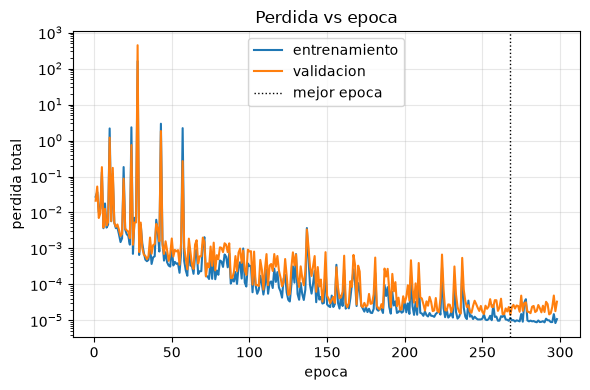

In [25]:
history = best.result.history
epochs = np.arange(1, len(history["train"]["total"]) + 1)

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(epochs, history["train"]["total"], label="entrenamiento")
ax.semilogy(epochs, history["val"]["total"], label="validacion")
ax.axvline(best.best_epoch, color="k", ls=":", lw=1, label="mejor epoca")
ax.set_xlabel("epoca")
ax.set_ylabel("perdida total")
ax.set_title("Perdida vs epoca")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


La perdida de parabolicidad vale exactamente $0$ en las epocas donde ningun punto muestreado viola la cota.

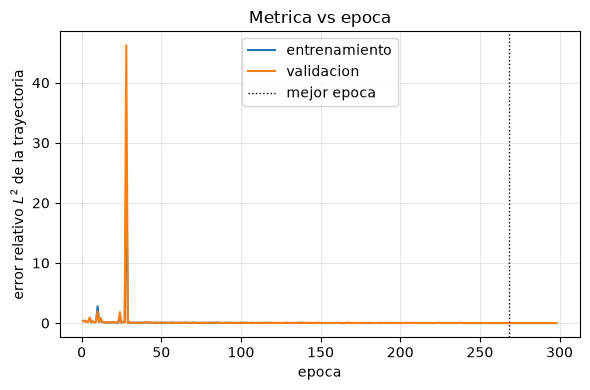

In [26]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(epochs, history["train"]["rel_l2"], label="entrenamiento")
ax.plot(epochs, history["val"]["rel_l2"], label="validacion")
ax.axvline(best.best_epoch, color="k", ls=":", lw=1, label="mejor epoca")
ax.set_xlabel("epoca")
ax.set_ylabel(r"error relativo $L^2$ de la trayectoria")
ax.set_title("Metrica vs epoca")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


**Nota:** La linea punteada vertical marca la epoca cuyos pesos restauro el early stopping.

## 6. Simbolo aprendido vs. referencia

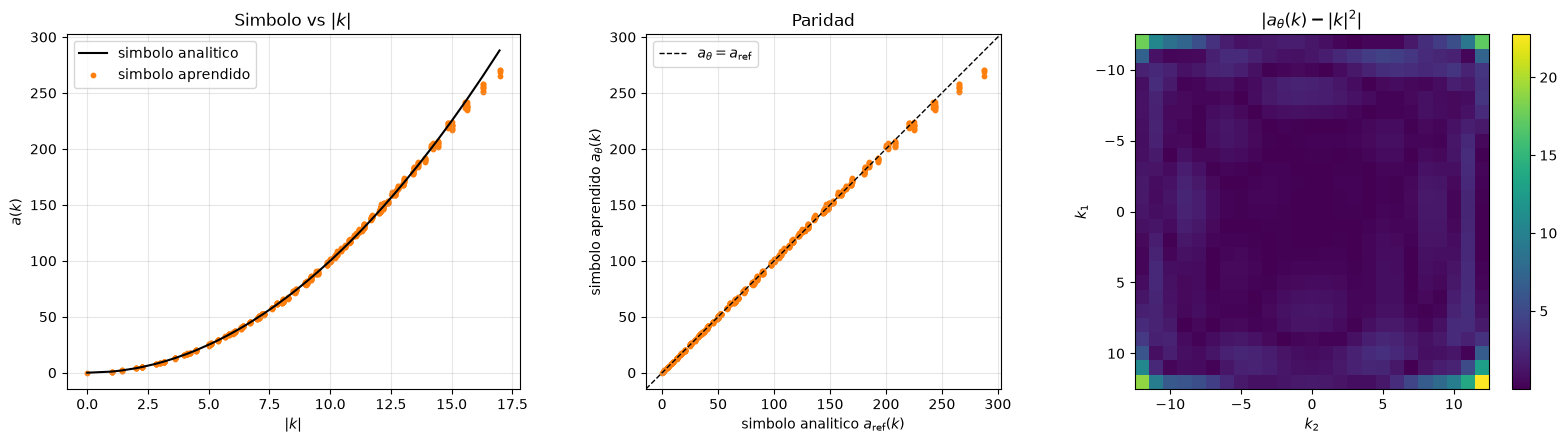

error relativo medio = 0.012, maximo = 0.084


In [27]:
k_arr = np.array(k_values)
a_true = np.array([reference(k)[0, 0] for k in k_values])
a_learn = symbol.evaluate_batch(k_arr)   # un solo forward por lotes
norm_k2 = np.sum(k_arr**2, axis=1)
norm_k = np.linalg.norm(k_arr, axis=1)

# Los dos simbolos son reales; np.real descarta la parte imaginaria nula que
# arrastra la interfaz compleja de Symbol.
a_ref_r, a_theta_r = np.real(a_true), np.real(a_learn)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# (a) La curva del simbolo. Para el calor, a(k) = |k|^2 es una parabola en |k|.
order = np.argsort(norm_k)
axes[0].plot(norm_k[order], a_ref_r[order], "k-", lw=1.5, label="simbolo analitico")
axes[0].scatter(norm_k, a_theta_r, s=10, color="C1", label="simbolo aprendido")
axes[0].set_xlabel(r"$|k|$")
axes[0].set_ylabel(r"$a(k)$")
axes[0].set_title(r"Simbolo vs $|k|$")
axes[0].legend()
axes[0].grid(alpha=0.3)

# (b) Paridad: cada k es un punto; sobre la diagonal significa que a_theta acerto.
lo = min(a_ref_r.min(), a_theta_r.min())
hi = max(a_ref_r.max(), a_theta_r.max())
pad = 0.05 * (hi - lo)
lims = [lo - pad, hi + pad]
axes[1].plot(lims, lims, "k--", lw=1, label=r"$a_\theta = a_{\text{ref}}$")
axes[1].scatter(a_ref_r, a_theta_r, s=10, color="C1")
axes[1].set_xlim(lims)
axes[1].set_ylim(lims)
axes[1].set_aspect("equal")
axes[1].set_xlabel(r"simbolo analitico $a_{\mathrm{ref}}(k)$")
axes[1].set_ylabel(r"simbolo aprendido $a_\theta(k)$")
axes[1].set_title("Paridad")
axes[1].legend()
axes[1].grid(alpha=0.3)

# (c) Error absoluto sobre la rejilla (k1, k2).
im = axes[2].imshow(
    np.abs(a_learn - a_true).reshape(2 * k_max + 1, 2 * k_max + 1),
    extent=[-k_max - 0.5, k_max + 0.5, k_max + 0.5, -k_max - 0.5],
)
axes[2].set_title(r"$|a_\theta(k) - |k|^2|$")
axes[2].set_xlabel(r"$k_2$")
axes[2].set_ylabel(r"$k_1$")
fig.colorbar(im, ax=axes[2])
plt.tight_layout()
plt.show()

rel = np.abs(a_learn - a_true) / np.maximum(norm_k2, 1)
print(f"error relativo medio = {rel.mean():.3f}, maximo = {rel.max():.3f}")


Para $|\mathbf{k}|$ grande $e^{-t|\mathbf{k}|^2}\approx 0$ en casi todo el rango de $t$, asi que la perdida de
trayectoria da poca informacion alli y el error es mayor.

## 7. Certificacion de Parabolicidad

La rejilla de seleccion (`lam_values` / `check_phase`) ya se uso para estimar $\hat\kappa$ y para
decidir que corridas cumplen, asi que no puede ademas certificar el resultado. Aqui se usa una
rejilla **independiente**, evaluada una sola vez sobre el modelo ya elegido:

- $k$ en $|k_i|\le 3k_{\max}$, tres veces la ventana de entrenamiento;
- $|\lambda|$ log-espaciado en $[10^{-2},10^{3}]$ con $25$ angulos en $[-\pi/2,\pi/2]$,
  extremos incluidos (la frontera $\mathrm{Re}(\lambda)=0$).


In [28]:
# Rejilla de CERTIFICACION: independiente de la de seleccion, solo se usa aqui.
cert_radii = np.logspace(-2, 3, 25)                    # |lambda| en [1e-2, 1e3]
cert_angles = np.linspace(-np.pi / 2, np.pi / 2, 25)   # incluye la frontera Re(lambda) = 0
cert_lam = (cert_radii[:, None] * np.exp(1j * cert_angles)).ravel()
cert_k_max = 3 * k_max


def cert_max_ratio(k_window, chunk=200_000):
    """Peor ratio sobre (|k_i| <= k_window) x cert_lam, por trozos para no llenar memoria."""
    kk, ll = phase_grid(n, k_window, cert_lam, device=device, dtype=dtype)
    return max(
        max_ratio_on(symbol, (kk[i : i + chunk], ll[i : i + chunk]), omega, best.kappa)
        for i in range(0, kk.shape[0], chunk)
    )


n_k_cert = len(k_grid(n, cert_k_max))
max_ratio = cert_max_ratio(cert_k_max)

print(f"{symbol!r}")
print(f"rejilla de certificacion: {n_k_cert:,} k (|k_i| <= {cert_k_max}) x "
      f"{len(cert_lam)} lambda = {n_k_cert * len(cert_lam):,} puntos")
print(f"kappa usada = {best.kappa:.4f}")
print(f"max ratio   = {max_ratio:.4f}   (<= 1 => la cota se cumple)")
print(f"cumple      = {max_ratio <= 1.0}")
print(f"kappa minimo que certificaria esta rejilla = {best.kappa * max_ratio:.4f}")


MLPSymbol(hidden=(128, 128, 128), sin dropout)(n=2, m=2.0, rho=3, dim=1)
rejilla de certificacion: 5,329 k (|k_i| <= 36) x 625 lambda = 3,330,625 puntos
kappa usada = 2.0000
max ratio   = 4.3795   (<= 1 => la cota se cumple)
cumple      = False
kappa minimo que certificaria esta rejilla = 8.7591


In [29]:
# Hasta donde alcanza: peor ratio por ventana de k, con la misma rejilla de lambda.
# La parabolicidad solo puede esperarse dentro de la ventana muestreada.
for window in (k_max, 2 * k_max, cert_k_max):
    ratio = cert_max_ratio(window)
    donde = "dentro" if window <= k_max else "fuera "
    print(f"|k_i| <= {window:3d} ({donde} de la ventana de entrenamiento): "
          f"max ratio = {ratio:.4f} -> {'cumple' if ratio <= 1.0 else 'NO cumple'}")


|k_i| <=  12 (dentro de la ventana de entrenamiento): max ratio = 1.1161 -> NO cumple
|k_i| <=  24 (fuera  de la ventana de entrenamiento): max ratio = 1.9418 -> NO cumple
|k_i| <=  36 (fuera  de la ventana de entrenamiento): max ratio = 4.3795 -> NO cumple
